# 02 · 实验可信度诊断与平均处理效应

本页读取统计产物，可以重新排版表格与绘制图表；单位转换、坐标轴和颜色只用于展示，不重新执行检验、置换、模型训练或结果写入。正文及注释使用中文，表格使用英文标签并隐藏默认索引。

**阅读顺序：平均效果 → 分配比例 → 单变量平衡 → 联合可区分性 → 结果可学习性。** 每个表只回答一个问题，共用的范围、样本量和计算精度在表外说明一次。

In [1]:
# 选择已有实验结果：优先本地；设置 CRITEO_RESULTS_MODE=published 可只读公开快照。
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "criteo_uplift").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from criteo_uplift.pipeline_io import result_directory

RUN = result_directory("conversion_1000000_seed42", ROOT)
manifest = json.loads((RUN / "manifest.json").read_text())
print("结果来源：", RUN.relative_to(ROOT))
# 只定义展示样式，不计算统计量、不写入项目结果。
TABLE_STYLES = [
    {"selector": "", "props": [("border-collapse", "collapse"), ("font-size", "14px"), ("min-width", "640px")]},
    {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#18364b"), ("padding", "10px 14px"), ("text-align", "right"), ("border-bottom", "2px solid #b9cddd")]},
    {"selector": "td", "props": [("padding", "9px 14px"), ("text-align", "right"), ("border-bottom", "1px solid #e3eaf0")]},
    {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f7fafc")]},
    {"selector": "td:first-child, th:first-child", "props": [("text-align", "left")]},
]

结果来源： artifacts/conversion_1000000_seed42


## 1. 全量平均效果：差异有多大，区间有多宽？

读取 `ate_full.csv`。ATE 是处理组结果率减去对照组结果率；表中差值与区间采用百分点（pp），两组结果率及相对提升采用百分比。图表恢复历史双子图设计，两个横轴分别缩放且保留零效应参考；粗区间线、大端点及小空心点帮助辨认较窄的 Visit 区间。

这是全量公开样本的描述性实验背景，不用于模型选择。P 值由同一双侧 pooled z 检验的稳定对数尾概率计算，科学计数文本约保留四位有效数字。`ln(P)` 保存自然对数；普通浮点 P 值下溢为零时，仍可用对数值表达量级，不能把它解释为真实概率为零。

Outcome,Control rate,Treatment rate,ATE (pp),95% CI (pp),Relative uplift,P-value,ln(P)
Conversion,0.1938%,0.3089%,+0.1152,"[+0.1085, +0.1219]",+59.45%,7.308e-179,-410.174
Visit,3.8201%,4.8543%,+1.0342,"[+1.0056, +1.0629]",+27.07%,4.387e-927,-2133.018


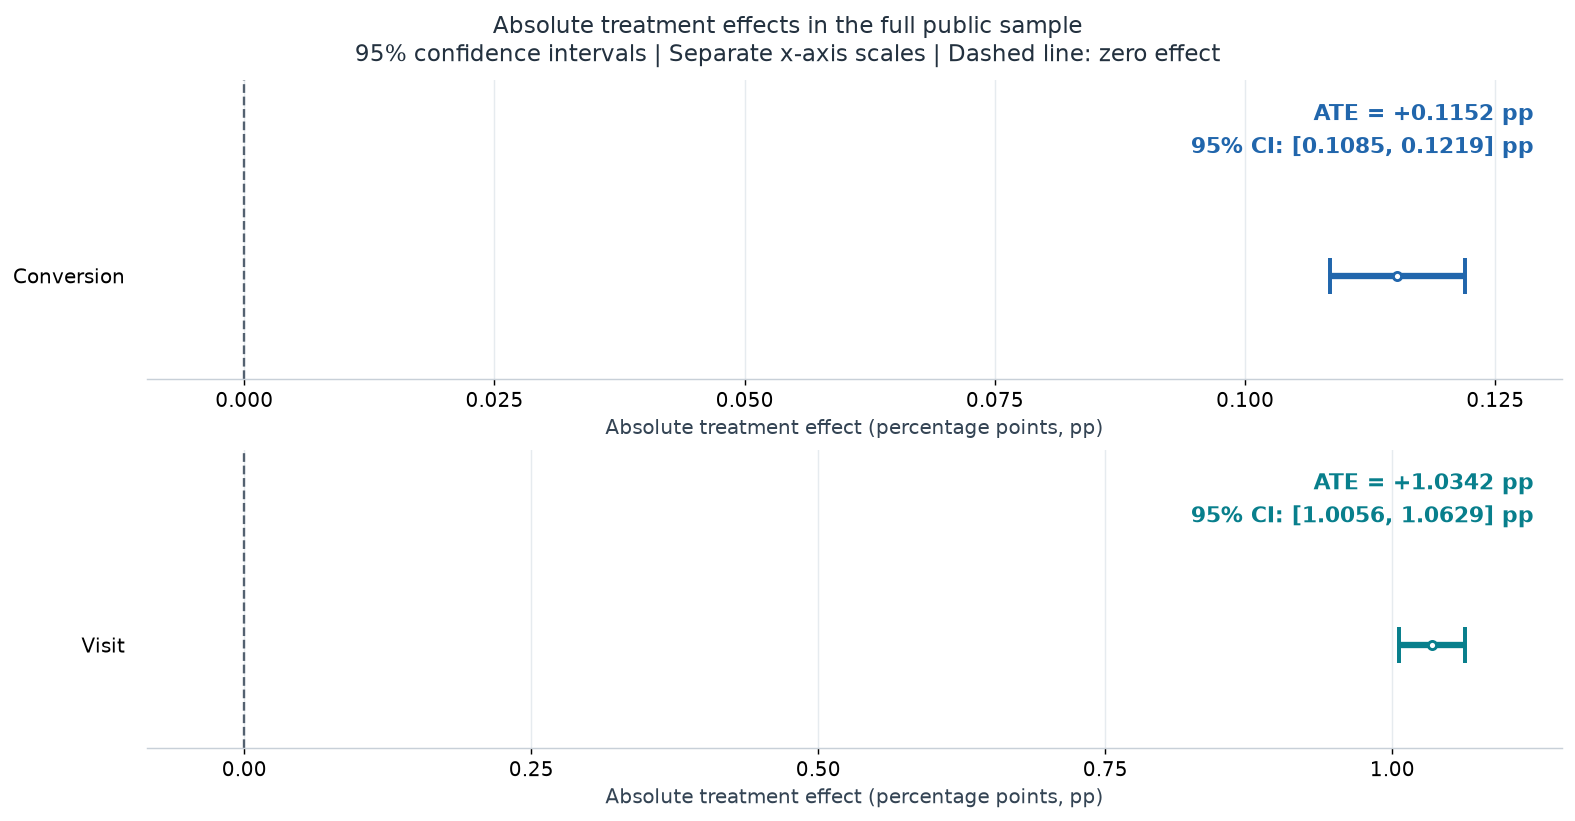

In [2]:
# 只转换显示单位并格式化，原始结果表保持不变。
ate = pd.read_csv(RUN / "diagnostics/ate_full.csv", dtype={"p_value_text": "string"})
ate_table = pd.DataFrame({
    "Outcome": ate["outcome"].str.capitalize(),
    "Control rate": ate["response_control"], "Treatment rate": ate["response_treatment"],
    "ATE (pp)": ate["ate"] * 100,
    "95% CI (pp)": [f"[{lo * 100:+.4f}, {hi * 100:+.4f}]" for lo, hi in zip(ate["ci_low"], ate["ci_high"])],
    "Relative uplift": ate["relative_uplift"], "P-value": ate["p_value_text"],
    "ln(P)": ate["log_p_value"],
})
display(ate_table.style.hide(axis="index").format({
    "Control rate": "{:.4%}", "Treatment rate": "{:.4%}", "ATE (pp)": "{:+.4f}",
    "Relative uplift": "{:+.2%}", "ln(P)": "{:.3f}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["95% CI (pp)"], **{"white-space": "nowrap"}))
# 从当前表格现场绘图；原始列保持比例单位，绘图副本转换为百分点（pp）。
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

ate_plot = (
    ate.set_index('outcome')
    .loc[['conversion', 'visit'], ['ate', 'ci_low', 'ci_high']]
    .mul(100) #转换成pp值
)

with plt.rc_context( # 使用with:设置临时的图片样式参数
    {
        'font.family': 'DejaVu Sans',
        'font.size': 11,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.spines.left': False,
        'axes.edgecolor': '#C8D0D8',
        'axes.labelcolor': '#344454',
        'text.color': '#23313F',
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    }
):
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 6.2),
        sharex=False,
        dpi=130,
        constrained_layout=True,
    )
    fig.suptitle(
        'Absolute treatment effects in the full public sample\n'
        '95% confidence intervals | Separate x-axis scales | Dashed line: zero effect',
        fontsize=13,
    )

    for ax, (outcome, row), color in zip(
        axes,
        ate_plot.iterrows(),
        ['#2166AC', '#087F8C'],
    ):
        ax.axvline(
            0,
            color='#536170',
            linestyle='--',
            linewidth=1.3,
            zorder=2,
        )
        ax.errorbar(
            x=[row['ate']],
            y=[0],
            xerr=[
                [row['ate'] - row['ci_low']],
                [row['ci_high'] - row['ate']],
            ],
            fmt='none',
            color=color,
            elinewidth=3.5,
            capsize=10,
            capthick=2.2,
            zorder=3,
        )

        # 单独绘制小型空心点，避免较窄的 Visit 区间被实心标记遮挡。
        ax.plot(row['ate'], 0, marker='o', markersize=4.5,
                markerfacecolor='white', markeredgecolor=color,
                markeredgewidth=1.6, linestyle='none', zorder=4)

        # 每个子图独立缩放，但始终包含零点、点估计和完整 CI；保持线性坐标。
        left = min(0.0, row['ci_low'], row['ate'])
        right = max(0.0, row['ci_high'], row['ate'])
        span = right - left
        padding = 0.08 * span if span > 0 else 0.01
        ax.set_xlim(
            left - padding,
            right + padding,
        )

        ax.set_ylim(-0.45, 0.85)
        ax.set_yticks(
            [0],
            [outcome.capitalize()],
        )
        ax.tick_params(axis='y', length=0, pad=12)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
        
        ax.set_xlabel('Absolute treatment effect (percentage points, pp)')
        ax.set_axisbelow(True)
        ax.grid(axis='x', color='#E6EBEF', linewidth=0.8)

        # 标注使用绘图区相对坐标，放在点和 CI 上方，避免遮挡。
        ax.text(
            0.98,
            0.94,
            f"ATE = {row['ate']:+.4f} pp\n"
            f"95% CI: [{row['ci_low']:.4f}, {row['ci_high']:.4f}] pp",
            transform=ax.transAxes,
            ha='right',
            va='top',
            fontsize=12,
            fontweight='bold',
            color=color,
            linespacing=1.5,
        )

    plt.show()


## 2. 分配比例：公开计数是否接近外部参考？

读取 `srm.json`。85% 是发布数据的外部参考比例，并非已知的原始实验设计参数。这里的显著或不显著均不能直接证明原始线上实验是否通过 SRM 或随机化。

In [3]:
# 样本量与范围只说明一次，表内聚焦观测比例、参考比例与检验结果。
srm = json.loads((RUN / "diagnostics/srm.json").read_text())
print(f"分析范围：全量公开数据｜Control：{srm['n_control']:,} 行｜Treatment：{srm['n_treatment']:,} 行")
srm_table = pd.DataFrame([srm])[["observed_ratio", "expected_ratio", "chi2", "pvalue", "status"]].rename(columns={
    "observed_ratio": "Observed treatment share", "expected_ratio": "Reference share",
    "chi2": "Chi-square", "pvalue": "P-value", "status": "Status",
})
display(srm_table.style.hide(axis="index").format({
    "Observed treatment share": "{:.6%}", "Reference share": "{:.2%}", "Chi-square": "{:.3e}", "P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
print("参考资料：", srm["reference_source"])

分析范围：全量公开数据｜Control：2,096,937 行｜Treatment：11,882,655 行


Observed treatment share,Reference share,Chi-square,P-value,Status
85.000013%,85.00%,1.818e-06,9.989e-01,computed


参考资料： https://arxiv.org/html/2111.10106#S3


## 3. 单变量平衡：哪些特征存在分布差异？

读取 `balance.csv`；范围与上节相同，使用原始 CSV 的 `float64` 表示。样本量、范围、精度和指纹不再逐特征重复列出。

SMD 用两组均值差除以组内方差的合并尺度，表示标准化后的平均差；KS D 比较两组经验分布函数的最大距离，能反映均值以外的分布差异。

表格按已保存的 `|SMD|` 排序，只保留两组均值、带方向的 SMD、KS 的 **D 统计量**及辅助 P 值。D 是经验分布函数的最大距离，不是乘以根号样本量后的量。大样本下优先看差异大小；KS P 值未经多重校正，不能仅凭显著性判定实际重要性。

In [4]:
# 选取与特征直接相关的列；排序只改变展示顺序，不重新计算统计量。
balance = pd.read_csv(RUN / "diagnostics/balance.csv")
balance_table = balance.sort_values("abs_smd", ascending=False)[[
    "feature", "mean_control", "mean_treatment", "smd", "ks_statistic", "ks_pvalue",
]].rename(columns={
    "feature": "Feature", "mean_control": "Control mean", "mean_treatment": "Treatment mean",
    "smd": "SMD", "ks_statistic": "KS D", "ks_pvalue": "KS P-value",
})
display(balance_table.style.hide(axis="index").format({
    "Control mean": "{:.5f}", "Treatment mean": "{:.5f}", "SMD": "{:+.6f}", "KS D": "{:.6f}", "KS P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["SMD", "KS D"], **{"font-weight": "600", "color": "#175c83"}))

Feature,Control mean,Treatment mean,SMD,KS D,KS P-value
f3,4.23282,4.16941,-0.048836,0.013794,5.007e-295
f6,-3.99988,-4.18279,-0.040448,0.013069,7.419e-265
f5,4.03934,4.02660,-0.030557,0.006099,5.198e-58
f9,15.88625,16.05259,+0.024001,0.007125,5.184e-79
f1,10.06794,10.07034,+0.023994,0.002662,2.119e-11
f8,3.93465,3.93339,-0.022433,0.008334,5.837e-108
f7,5.08028,5.10556,+0.021270,0.006099,5.198e-58
f10,5.33190,5.33366,+0.010563,0.002415,1.882e-09
f4,10.33653,10.33925,+0.007966,0.002412,1.959e-09
f0,19.65170,19.61476,-0.006866,0.008950,1.913e-124


## 4. 联合可区分性：模型能否区分两组？

C2ST 从全量来源按组等概率无放回抽样，构造两组等量的诊断样本；它不等于建模样本，也不使用正式测试集选模。

固定分类器为标准化 Logistic 与 XGBoost（30 棵树、最多 15 个叶节点，直方图训练）。`binary:logistic` 是树模型内部优化目标，外部检验统计量仍为留出 ROC-AUC；辅助保留 Log loss、Brier 和 AP。内部训练／留出各自置换 treatment，并完整重拟合固定分类器。关注留出 AUC 与 Holm 校正后的 P 值：AUC 的随机基准为 0.5；不显著不证明联合分布相同，显著也不能单独证明随机化失败。

诊断样本：Control 10,000 行 + Treatment 10,000 行；内部训练／留出为 70%／30%。
随机种子：42｜完整重拟合置换：499 次｜P 值分辨率：0.0020｜两模型 Holm 校正。
Dummy 基线对所有行输出内部训练集的 Treatment 占比；这里只展示预测指标，不进行额外检验。


Model,Holdout ROC AUC,Permutation P-value,Holm P-value,Log loss,Brier,AP
dummy,0.5000,—,—,0.69315,0.25000,0.5000
logistic,0.5177,0.006,0.012,0.69253,0.24969,0.5188
xgboost,0.5008,0.446,0.446,0.69497,0.25087,0.5025


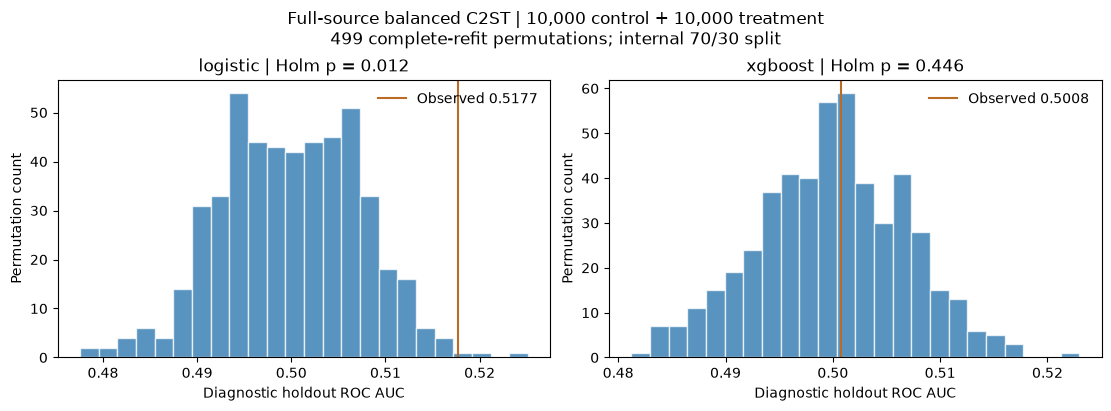

In [5]:
# 共用的抽样与置换配置只在表外展示；表内每行只保留模型自身结果。
c2st = pd.read_csv(RUN / "diagnostics/c2st.csv")
details = json.loads((RUN / "diagnostics/c2st_details.json").read_text())
print(f"诊断样本：Control {details['n_control']:,} 行 + Treatment {details['n_treatment']:,} 行；内部训练／留出为 70%／30%。")
print(f"随机种子：{details['seed']}｜完整重拟合置换：{details['permutations']:,} 次｜P 值分辨率：{details['pvalue_resolution']:.4f}｜两模型 Holm 校正。")
c2st_table = c2st[["model", "roc_auc", "pvalue", "pvalue_holm", "log_loss", "brier", "average_precision"]].rename(columns={
    "model": "Model", "roc_auc": "Holdout ROC AUC", "pvalue": "Permutation P-value", "pvalue_holm": "Holm P-value",
    "log_loss": "Log loss", "brier": "Brier", "average_precision": "AP",
})
# 常数预测基线：前三项指标已保存；常数评分的 AP 等于已保存的留出集正例比例。
# 基线只用于比较预测表现，不新增置换检验或参与两模型的 Holm 校正。
baseline = c2st.iloc[0]
baseline_table = pd.DataFrame([{
    "Model": "dummy",
    "Holdout ROC AUC": baseline["dummy_roc_auc"],
    "Permutation P-value": float("nan"),
    "Holm P-value": float("nan"),
    "Log loss": baseline["dummy_log_loss"],
    "Brier": baseline["dummy_brier"],
    "AP": baseline["test_treatment_ratio"],
}])
c2st_table = pd.concat([baseline_table, c2st_table], ignore_index=True)
print("Dummy 基线对所有行输出内部训练集的 Treatment 占比；这里只展示预测指标，不进行额外检验。")
display(c2st_table.style.hide(axis="index").format({
    "Holdout ROC AUC": "{:.4f}", "Permutation P-value": "{:.3f}", "Holm P-value": "{:.3f}", "Log loss": "{:.5f}", "Brier": "{:.5f}", "AP": "{:.4f}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
# 直接从原来的 c2st_null.csv 现场绘制置换零分布。
null = pd.read_csv(
    (RUN / 'diagnostics' / 'c2st_null.csv')
)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True,
)
for ax, row in zip(axes, c2st.itertuples()):
    ax.hist(
        null.loc[null['model'] == row.model, 'roc_auc'],
        bins=24, color='#2171ad', alpha=.75, edgecolor='white',
    )
    ax.axvline(
        row.roc_auc, color='#ba6b24', label=f'Observed {row.roc_auc:.4f}',
    )
    ax.set_title(f'{row.model} | Holm p = {row.pvalue_holm:.3f}')
    ax.set_xlabel('Diagnostic holdout ROC AUC')
    ax.set_ylabel('Permutation count')
    ax.legend(frameon=False)
fig.suptitle(
    f"Full-source balanced C2ST | {details['n_control']:,} control + "
    f"{details['n_treatment']:,} treatment\n"
    f"{details['permutations']} complete-refit permutations; internal 70/30 split"
)
plt.show()

## 5. 结果可学习性：特征能预测结果吗？

读取 `learnability.csv`，默认查看整个训练／验证集范围（`whole`），按结果指标分别比较 Dummy 与固定模型。可修改下方 `LEARNING_SCOPE` 以查看某个已保存的分组，选项以输出提示为准。

Dummy 只输出训练集正例率，作为没有特征信息的基准；模型在训练集拟合、在验证集评价。ROC AUC／AP 越高越好，Log loss／Brier 越低越好；AP 应结合验证集正例率阅读。结果可预测不等于 CATE 可预测，也不能代替策略增量评价。

In [6]:
# 仅筛选已有范围与结果；各模型共用的样本量和正例率在表外展示。
LEARNING_SCOPE = "whole"
learning = pd.read_csv(RUN / "diagnostics/learnability.csv")
print("已保存的分析范围：", ", ".join(learning["scope"].unique()))
learning_view = learning.loc[learning["scope"] == LEARNING_SCOPE]
if learning_view.empty:
    print("该结果文件没有所选范围，请从上面的范围中选择。")
for outcome in learning_view["outcome"].unique():
    rows = learning_view.loc[learning_view["outcome"] == outcome]
    context = rows.iloc[0]
    print(f"分析指标：{outcome}｜范围：{LEARNING_SCOPE}｜训练 {context['n_train']:,} 行，验证 {context['n_validation']:,} 行")
    print(f"正例率：训练 {context['positive_rate_train']:.4%}，验证 {context['positive_rate_validation']:.4%}")
    table = rows[["model", "roc_auc", "average_precision", "log_loss", "brier", "status"]].rename(columns={
        "model": "Model", "roc_auc": "ROC AUC", "average_precision": "AP", "log_loss": "Log loss", "brier": "Brier", "status": "Status",
    })
    display(table.style.hide(axis="index").format({
        "ROC AUC": "{:.4f}", "AP": "{:.4f}", "Log loss": "{:.5f}", "Brier": "{:.5f}",
    }, na_rep="—").set_table_styles(TABLE_STYLES))

已保存的分析范围： whole, treatment, control
分析指标：visit｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 4.6762%，验证 4.6870%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0469,0.18919,0.04467,computed
logistic,0.9320,0.4785,0.11161,0.03141,computed
xgboost,0.9443,0.5035,0.10520,0.03015,computed


分析指标：conversion｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 0.2882%，验证 0.2880%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0029,0.01972,0.00287,computed
logistic,0.9460,0.1926,0.01264,0.00258,computed
xgboost,0.9502,0.2268,0.01212,0.00251,computed


## 解释边界与刷新方式

这些诊断不证明用户级独立、特征生成时点有效、随机化成立或真实投放收益。公开数据经过发布处理，未知用户依赖、实验分块与跨实验结构仍属于限制。不要根据这些已查看的结果反复调整测试集或正式模型选择。

本页不自动生成“通过／失败”的统计结论，也不重复打印前面各表的数据。要重新运行诊断，应在终端明确执行主流程的 `--diagnostics-only` 模式；这会补齐缺失审计字段、统一汇总标签、更新 ATE 尾概率表示，并重做 C2ST／结果可学习性诊断；既有划分、正式模型及 ATE 点估计和区间保持原口径，与重新运行本页展示单元格不同。详见 [项目流程](../docs/PROJECT_PIPELINE.md)。